In [1]:
print("Car Price Prediction Project Started!")
import sys
print("Python Version:", sys.version)

Car Price Prediction Project Started!
Python Version: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import pandas as pd
df = pd.read_csv("car data.csv")
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
# Dimensions 
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [5]:
# CDC
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

Total Duplicate Rows: 2


In [6]:
# RDR
df = df.drop_duplicates()

# Check dataset shape after removing duplicates
print("Dataset Shape After Removing Duplicates:", df.shape)

# Verify duplicates are removed
print("Remaining Duplicate Rows:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (299, 9)
Remaining Duplicate Rows: 0


In [7]:
# SSONC
df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.566332,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [8]:
# Check unique values in categorical columns
print("Fuel Types:")
print(df["Fuel_Type"].value_counts())

print("\nSelling Types:")
print(df["Selling_type"].value_counts())

print("\nTransmission Types:")
print(df["Transmission"].value_counts())

Fuel Types:
Fuel_Type
Petrol    239
Diesel     58
CNG         2
Name: count, dtype: int64

Selling Types:
Selling_type
Dealer        193
Individual    106
Name: count, dtype: int64

Transmission Types:
Transmission
Manual       260
Automatic     39
Name: count, dtype: int64


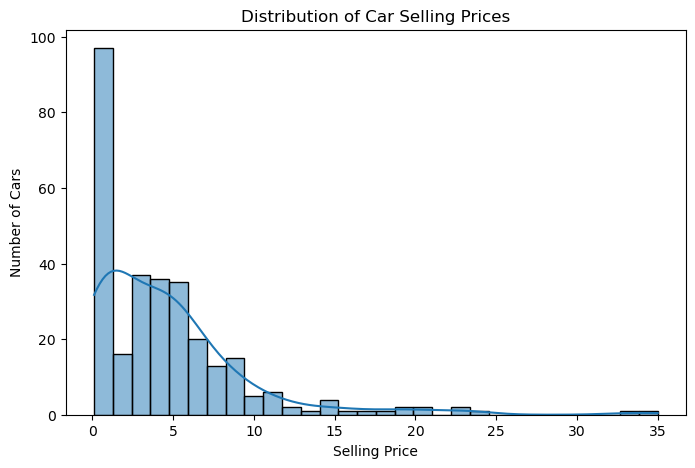

In [9]:
# Selling Price Distribution
plt.figure(figsize=(8, 5))

sns.histplot(df["Selling_Price"], bins=30, kde=True)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")

plt.show()

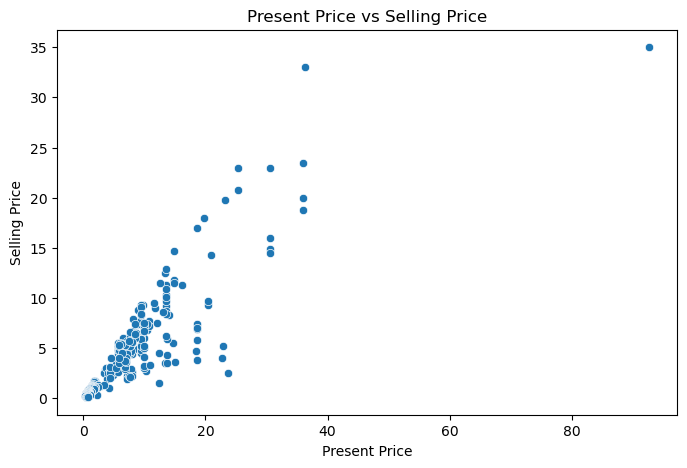

In [10]:
# Present Price vs Selling Price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Present_Price",
    y="Selling_Price",
    data=df
)

plt.title("Present Price vs Selling Price")
plt.xlabel("Present Price")
plt.ylabel("Selling Price")

plt.show()

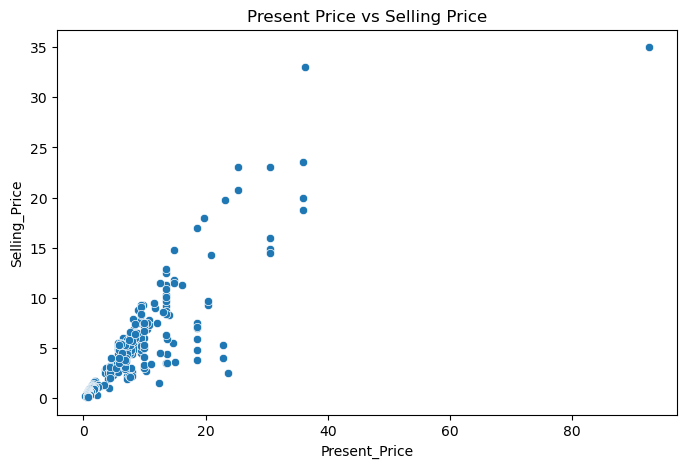

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Present_Price",
    y="Selling_Price",
    data=df
)

plt.title("Present Price vs Selling Price")
plt.show()

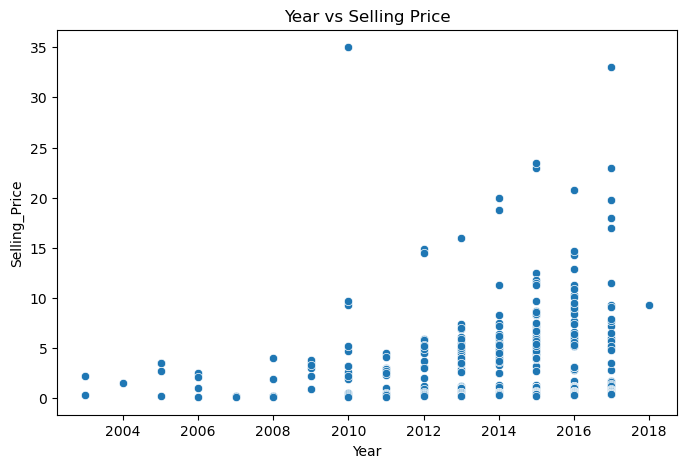

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Year",
    y="Selling_Price",
    data=df
)

plt.title("Year vs Selling Price")
plt.show()

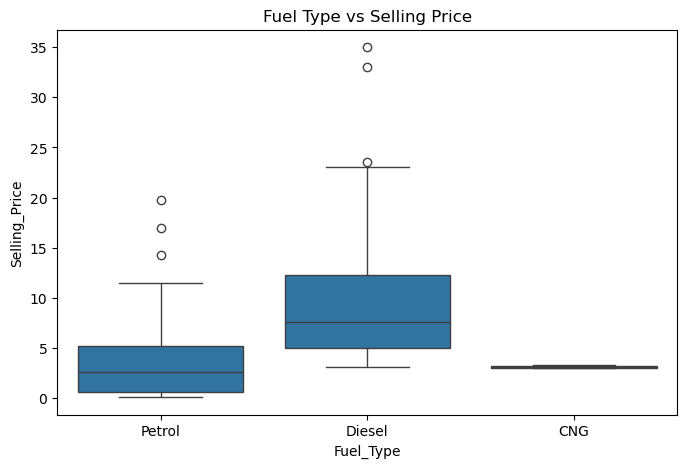

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Fuel_Type",
    y="Selling_Price",
    data=df
)

plt.title("Fuel Type vs Selling Price")
plt.show()

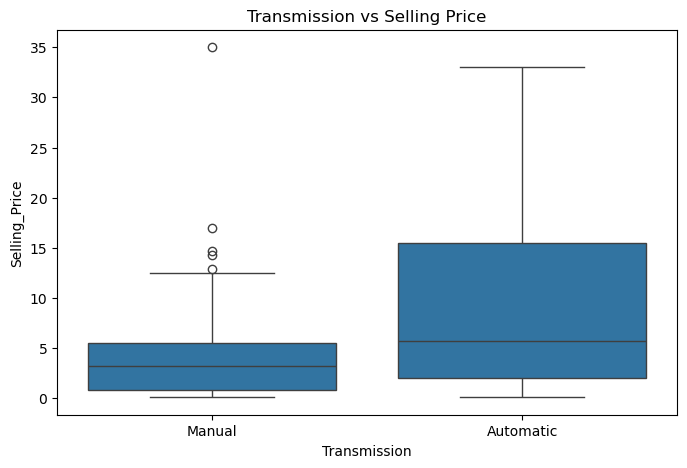

In [14]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Transmission",
    y="Selling_Price",
    data=df
)

plt.title("Transmission vs Selling Price")
plt.show()

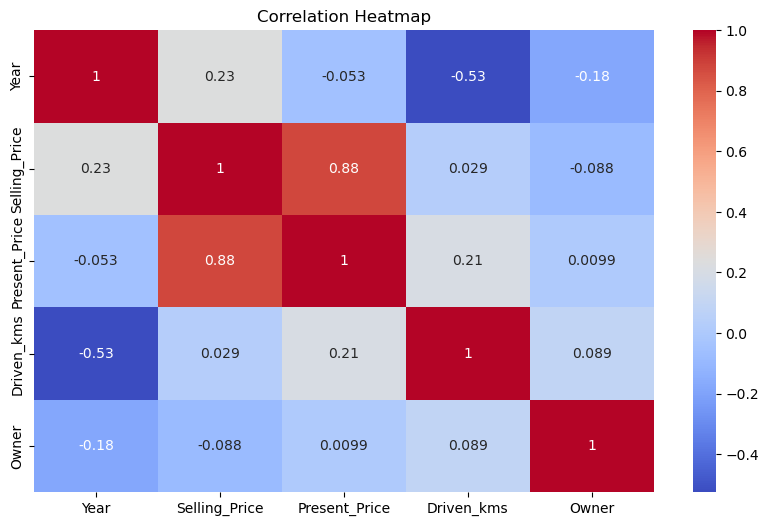

In [15]:
plt.figure(figsize=(10, 6))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [16]:
df["Car_Age"] = 2018 - df["Year"]

df[["Year", "Car_Age"]].head()

,Year,Car_Age
0,2014,4
1,2013,5
2,2017,1
3,2011,7
4,2014,4


In [17]:
df = df.drop(["Car_Name", "Year"], axis=1)

df.head()

,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,4
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,5
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,1
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,7
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,4


In [18]:
df = pd.get_dummies(
    df,
    columns=["Fuel_Type", "Selling_type", "Transmission"],
    drop_first=True,
    dtype=int
)

df.head()

,Selling_Price,Present_Price,Driven_kms,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Selling_type_Individual,Transmission_Manual
0,3.35,5.59,27000,0,4,0,1,0,1
1,4.75,9.54,43000,0,5,1,0,0,1
2,7.25,9.85,6900,0,1,0,1,0,1
3,2.85,4.15,5200,0,7,0,1,0,1
4,4.60,6.87,42450,0,4,1,0,0,1


In [19]:
print(df.shape)
print(df.dtypes)
print(df.isnull().sum())

(299, 9)
Selling_Price              float64
Present_Price              float64
Driven_kms                   int64
Owner                        int64
Car_Age                      int64
Fuel_Type_Diesel             int64
Fuel_Type_Petrol             int64
Selling_type_Individual      int64
Transmission_Manual          int64
dtype: object
Selling_Price              0
Present_Price              0
Driven_kms                 0
Owner                      0
Car_Age                    0
Fuel_Type_Diesel           0
Fuel_Type_Petrol           0
Selling_type_Individual    0
Transmission_Manual        0
dtype: int64


In [20]:
X = df.drop("Selling_Price", axis=1)

y = df["Selling_Price"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (299, 8)
Target Shape: (299,)


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (239, 8)
Testing Data: (60, 8)


In [22]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

In [23]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(name, actual, predicted):
    print("\n", name)
    print("MAE:", mean_absolute_error(actual, predicted))
    print("MSE:", mean_squared_error(actual, predicted))
    print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
    print("R2 Score:", r2_score(actual, predicted))

evaluate_model("Linear Regression", y_test, lr_predictions)

evaluate_model("Random Forest", y_test, rf_predictions)


 Linear Regression
MAE: 1.4725457508178648
MSE: 6.373125106260713
RMSE: 2.524504923001877
R2 Score: 0.7527233824220483

 Random Forest
MAE: 1.4656383333333347
MSE: 12.317244055166675
RMSE: 3.5095931466719437
R2 Score: 0.5220921609005125


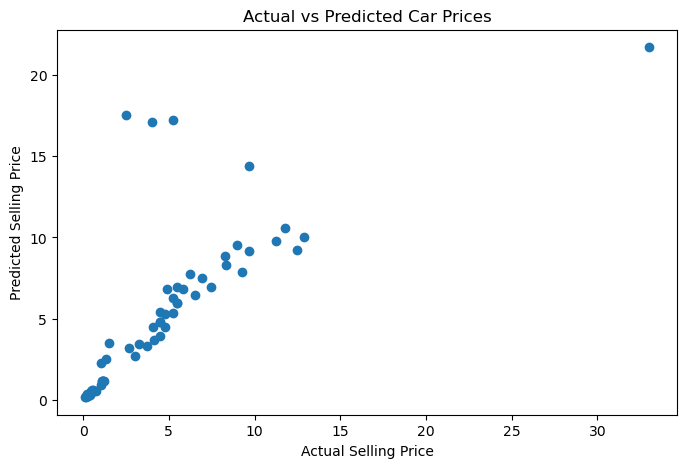

In [25]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()

In [26]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 300}


In [27]:
best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

evaluate_model("Optimized Random Forest", y_test, best_predictions)


 Optimized Random Forest
MAE: 1.5076375567195142
MSE: 13.031767234080709
RMSE: 3.6099539102432745
R2 Score: 0.49436873292491246


In [28]:
import pickle

with open("car_price_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

print("Model Saved Successfully!")

Model Saved Successfully!


In [29]:
with open("car_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

sample_prediction = loaded_model.predict(X_test.iloc[[0]])

print("Predicted Price:", sample_prediction[0])
print("Actual Price:", y_test.iloc[0])

Predicted Price: 9.463338227513228
Actual Price: 8.99


In [30]:
print(X_train.columns.tolist())

['Present_Price', 'Driven_kms', 'Owner', 'Car_Age', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Selling_type_Individual', 'Transmission_Manual']
